# Figure 1: Multi-omic cis-QTL discovery and fine-mapping

Current Figure 1 from the November 2, 2026 Science submission. The notebook rebuilds plots from saved results. It does not repeat association testing, novelty annotation, or fine-mapping. The final cell shows the exact submitted image.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_PAPER_ROOT` to the local
paper directory and `QTL_SOURCE_ROOT` to the figure checkout with staged inputs
and saved objects. For example, set these variables in the R session before
you run the cells. Paths can contain spaces.

Run the cells from top to bottom. The notebook reads the recorded figure data.
It does not rerun upstream QTL mapping unless a section explicitly says so.
New PDFs and PNGs go to `notebook_outputs/`. Inputs stay in place.
The source scripts are in `notebooks/current/`. Figures shown below are aggregate
plots. Do not print participant tables into a saved notebook.


## Scope

The notebook replots saved results. It does not validate or rerun upstream association tests, novelty calls, annotation downloads, or SuSiE fits.

Panel A is an R schematic of the saved counts and workflow. The exact submitted icons and vector layout are in the reference image and archived SVG.

Panel B uses the reconciled current data and saved layer coordinates. Its R reconstruction precedes the final measured gene-label spacing in the archived composition.

The rebuilt panels expose plotting code and saved values. The exact reference is the authoritative submitted page layout.

Novel target-gene status does not establish a new independent signal or a disease mechanism. Annotation categories can overlap.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the November 2 figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  path <- file.path(root, relative)
  if (!file.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  input_records[[paste(variable, relative, sep = ":")]] <- list(
    root = variable, path = relative, md5 = unname(tools::md5sum(path)))
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display the archived November 2 submission image for Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Inputs and plotting rules

This notebook rebuilds Figure 1 plots from the saved November 2 submission inputs.
The association tests, novelty calls, annotations, and fine-mapping models are saved results.
No model is fitted here. Each displayed value is an aggregate or a variant-trait statistic.
The last cell shows the exact submitted image. The R panels make the saved plot steps explicit.


In [2]:
suppressPackageStartupMessages(library(tidyverse))
suppressPackageStartupMessages(library(patchwork))
assays <- c("eQTL", "sQTL", "pQTL")
assay_colours <- c(eQTL = "#00798C", sQTL = "#EDAE49", pQTL = "#D1495B")
fig1_build <- "output/figure1_flowchart_draft"
fig1_print <- file.path(fig1_build, "science_print_size")
fig1_circos <- "output/qtl_circos_simplified_options/N_main_figure_reconciled_20261027"
fig1_categories <- "output/figure1_novel_gene_categories/seven_categories_20261027"
read_figure_tsv <- function(relative, ...) {
  readr::read_tsv(paper_file(relative), show_col_types = FALSE, progress = FALSE, ...)
}
fig1_theme <- theme_classic(base_size = 8, base_family = "Arial") +
  theme(axis.text = element_text(colour = "#263B45"),
        axis.line = element_line(linewidth = .25, colour = "#53616A"),
        axis.ticks = element_line(linewidth = .25, colour = "#53616A"),
        legend.title = element_blank(), plot.title = element_blank(),
        plot.subtitle = element_blank())
message("Figure 1 uses saved results from the November 2, 2026 submission.")


Figure 1 uses saved results from the November 2, 2026 submission.


## Panel A: Cohort counts and analysis workflow

Read the saved counts by ancestry group. These counts are before quality control (QC).
The separate cohort table records 8,895 RNA samples and 9,581 proteome samples after QC.
REM means remaining. The input table retains its original ancestry code, oth.
This R schematic shows the counts and analysis steps. The exact submitted icon artwork and vector layout are in the final reference image.


Export aggregate plot: Fig1_A_rebuilt


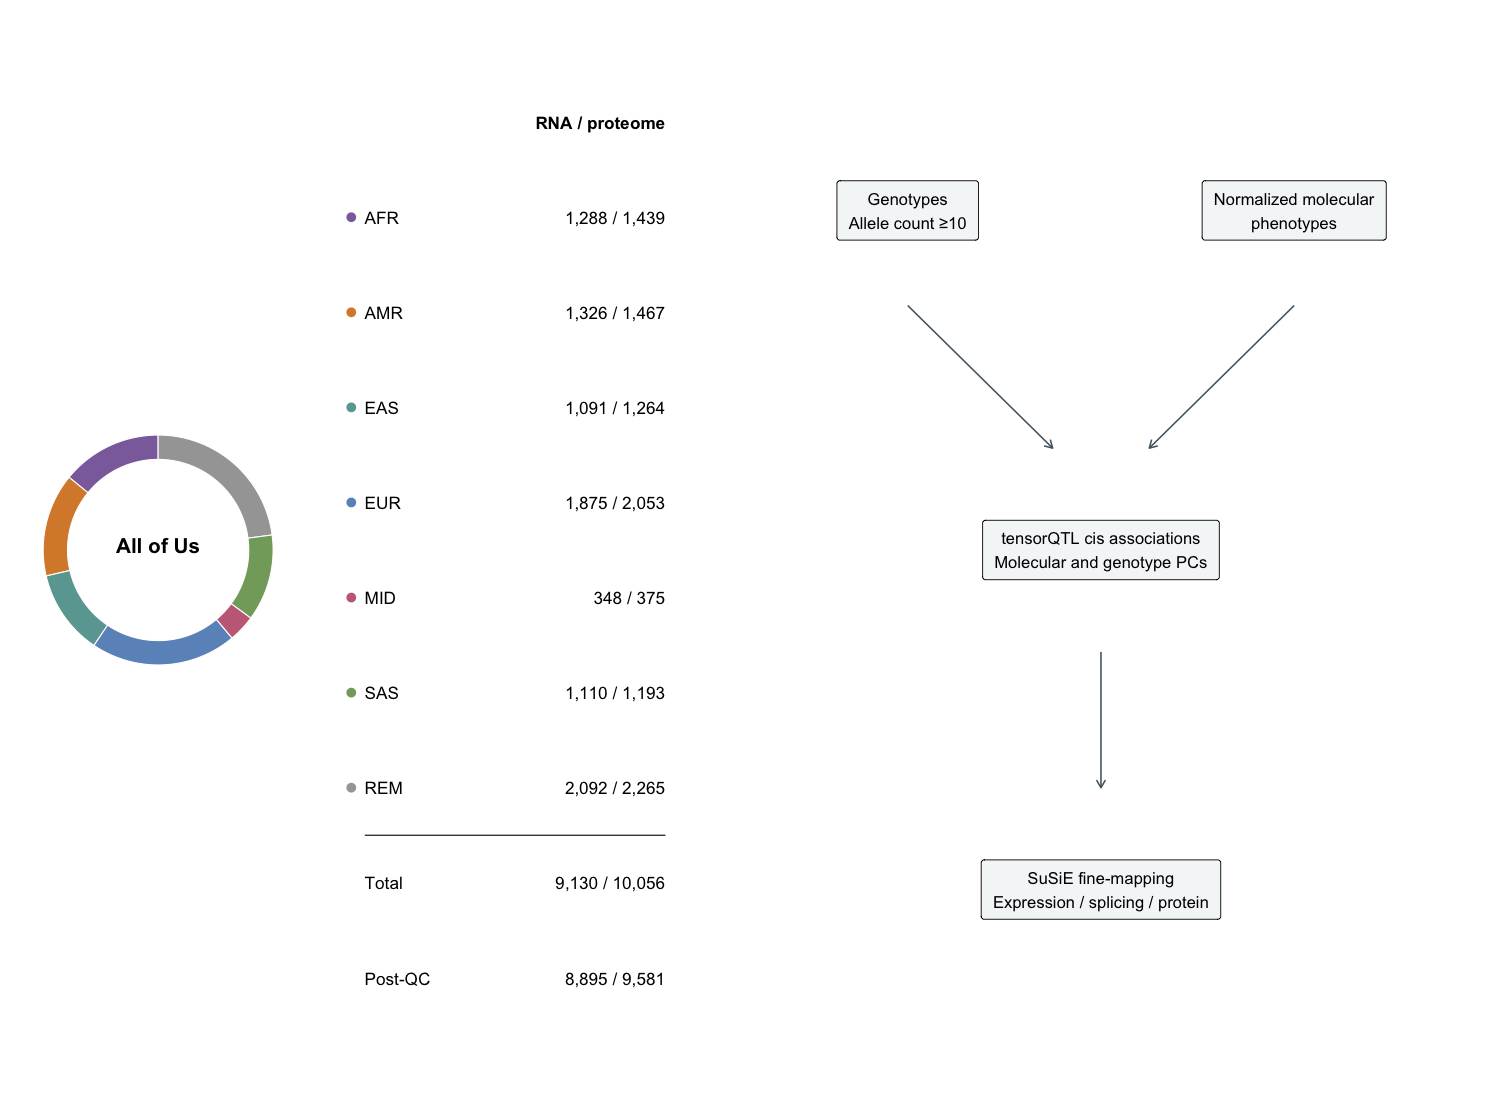

In [3]:
ancestry_levels <- c("AFR", "AMR", "EAS", "EUR", "MID", "SAS", "REM")
ancestry_colours <- c(AFR = "#8D6EAB", AMR = "#D98A38", EAS = "#6AA6A1",
                      EUR = "#6B94C4", MID = "#C56D85", SAS = "#83A86C", REM = "#A5A5A5")
cohort <- read_figure_tsv(file.path(fig1_print, "cohort_counts_2026-10-26.tsv")) %>%
  transmute(assay = recode(name, has_rna = "RNA", has_proteome = "Proteome"),
            ancestry = recode(str_to_upper(ancestry_pred_other), OTH = "REM"), n) %>%
  mutate(ancestry = factor(ancestry, levels = ancestry_levels))
cohort_totals <- read_figure_tsv(file.path(fig1_print,
  "Figure1_Science_184mm_seven_categories_postQC_20261027_cohort_totals.tsv"))
stopifnot(sum(cohort$n[cohort$assay == "RNA"]) == 9130L,
          sum(cohort$n[cohort$assay == "Proteome"]) == 10056L,
          cohort_totals$RNA[cohort_totals$category == "Post-QC"] == 8895L,
          cohort_totals$Proteome[cohort_totals$category == "Post-QC"] == 9581L)
cohort_rows <- cohort %>% pivot_wider(names_from = assay, values_from = n) %>%
  arrange(ancestry) %>% mutate(label = as.character(ancestry)) %>%
  bind_rows(cohort_totals %>% mutate(label = category) %>% select(-category)) %>%
  mutate(y = rev(seq_len(n())),
         count_label = paste(scales::comma(RNA), scales::comma(Proteome), sep = " / "))
p1A_counts <- ggplot(cohort_rows) +
  geom_point(data = cohort_rows %>% filter(label %in% ancestry_levels),
             aes(x = -.045, y = y, fill = label), shape = 21, size = 2.2, stroke = 0) +
  geom_text(aes(x = 0, y = y, label = label), hjust = 0, size = 2.9, family = "Arial") +
  geom_text(aes(x = 1, y = y, label = count_label), hjust = 1, size = 2.9, family = "Arial") +
  annotate("text", x = 1, y = 10, label = "RNA / proteome", hjust = 1,
           size = 2.9, fontface = "bold", family = "Arial") +
  annotate("segment", x = 0, xend = 1, y = 2.5, yend = 2.5, linewidth = .25) +
  scale_fill_manual(values = ancestry_colours, guide = "none") +
  coord_cartesian(xlim = c(-.06, 1.02), ylim = c(.5, 10.5), clip = "off") +
  theme_void(base_family = "Arial") + theme(plot.margin = margin(2, 4, 2, 4, "mm"))
rna_ring <- cohort %>% filter(assay == "RNA")
p1A_ring <- ggplot(rna_ring, aes(x = 2, y = n, fill = ancestry)) +
  geom_col(width = .45, colour = "white", linewidth = .25) +
  annotate("text", x = .2, y = 0, label = "All of Us", fontface = "bold", size = 3.5,
           family = "Arial") +
  coord_polar(theta = "y") + xlim(.1, 2.3) +
  scale_fill_manual(values = ancestry_colours, guide = "none") + theme_void()
workflow <- tribble(
  ~x, ~y, ~label,
  1, 3, "Genotypes\nAllele count \u226510",
  3, 3, "Normalized molecular\nphenotypes",
  2, 2, "tensorQTL cis associations\nMolecular and genotype PCs",
  2, 1, "SuSiE fine-mapping\nExpression / splicing / protein"
)
workflow_arrows <- tribble(~x, ~y, ~xend, ~yend,
                           1, 2.72, 1.75, 2.3,
                           3, 2.72, 2.25, 2.3,
                           2, 1.7, 2, 1.3)
p1A_workflow <- ggplot(workflow, aes(x, y)) +
  geom_segment(data = workflow_arrows, aes(x, y, xend = xend, yend = yend),
               inherit.aes = FALSE, linewidth = .35, colour = "#52656F",
               arrow = grid::arrow(length = grid::unit(1.5, "mm"))) +
  geom_label(aes(label = label), size = 2.8, family = "Arial", linewidth = .2,
             fill = "#F4F7F8", label.padding = grid::unit(2, "mm")) +
  coord_cartesian(xlim = c(.25, 3.75), ylim = c(.6, 3.4), clip = "off") +
  theme_void() + theme(plot.margin = margin(3, 3, 3, 3, "mm"))
p1A <- p1A_ring + p1A_counts + p1A_workflow + plot_layout(widths = c(1, 1.2, 2.5))
save_plot(p1A, "Fig1_A_rebuilt", width_mm = 184, height_mm = 58)
print(p1A)


## Panel B: Reconciled novel cis-QTL circos plot

Each point is the saved lead cis-variant for one molecular trait with q < 0.05.
Novelty is specific to the assay. It does not prove that an independent signal is new.
The pQTL novelty calls use the corrected UKBB protein target identities.
Source P values of zero stay censored. Radial scores are capped at 200 for eQTLs and sQTLs, and 150 for pQTLs.
This cell rebuilds the circos layers from the reconciled points, axes, and label tables.
The archived vector composition adds the final measured label gaps. The final reference retains those exact changes.


Export aggregate plot: Fig1_B_rebuilt


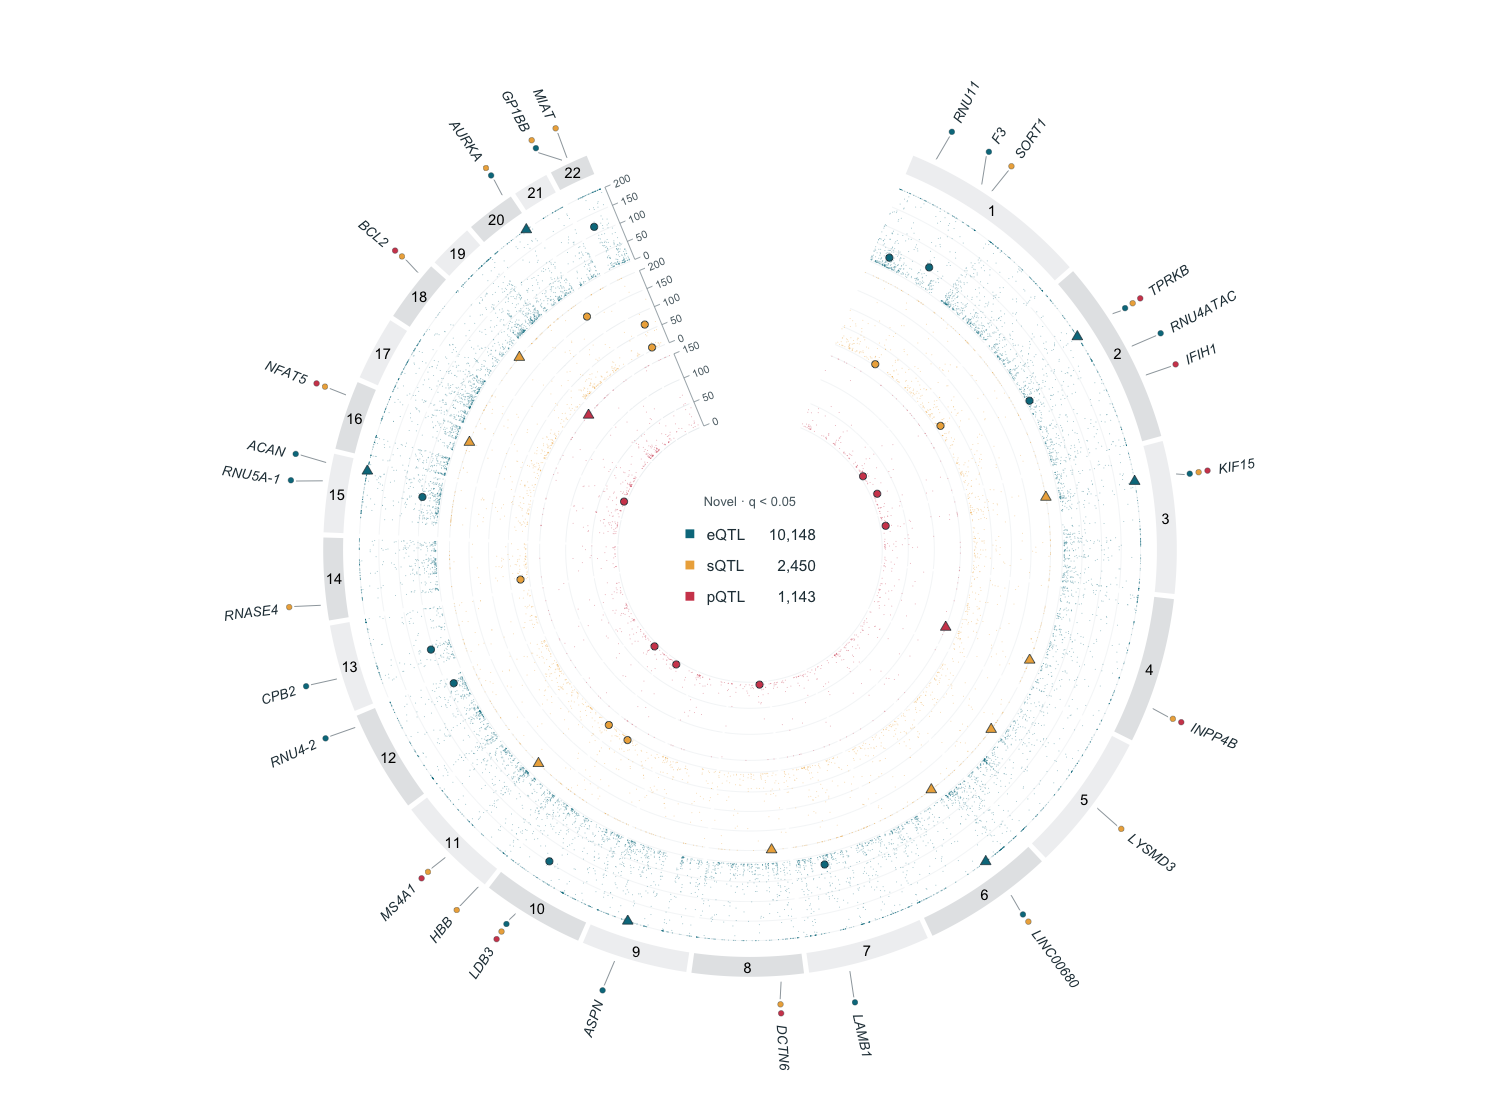

In [4]:
lead_points <- read_figure_tsv(file.path(fig1_circos, "plotted_lead_variants.tsv.gz"),
  col_types = cols(source_pval_nominal = col_character(),
                   source_pval_beta = col_character(), source_qval = col_character())) %>%
  mutate(assay = factor(assay, levels = assays))
novelty <- read_figure_tsv(file.path(fig1_circos, "paper_novelty_by_trait.tsv"))
anchors <- read_figure_tsv(file.path(fig1_circos, "label_anchors.tsv"))
label_dots <- read_figure_tsv(file.path(fig1_circos, "gene_label_dot_types.tsv"))
leaders <- read_figure_tsv(file.path(fig1_circos, "gene_connector_segments.tsv"))
axis_positions <- read_figure_tsv(file.path(fig1_circos, "axis_positions.tsv"))
axis_ticks <- read_figure_tsv(file.path(fig1_circos, "axis_ticks.tsv"))
highlights <- read_figure_tsv(file.path(fig1_circos, "highlighted_gene_signals.tsv")) %>%
  select(label, assay, phenotype_id) %>%
  left_join(lead_points, by = c("assay", "phenotype_id"), relationship = "many-to-one") %>%
  mutate(point_fill = unname(assay_colours[as.character(assay)]))
circos_counts <- lead_points %>% group_by(assay) %>%
  summarise(n_genes = n_distinct(gene_id), .groups = "drop")
stopifnot(identical(circos_counts$n_genes, c(10148L, 2450L, 1143L)),
          nrow(anchors) == 26L, nrow(label_dots) == 40L,
          all(lead_points$significant), all(is.finite(lead_points$x)),
          all(is.finite(lead_points$y)),
          nrow(anti_join(lead_points, novelty %>% filter(novel_for_figure),
                        by = c("assay", "phenotype_id"))) == 0L)
# Chromosome angles and radial coordinates were saved with each plotted point.
chromosomes <- lead_points %>%
  distinct(chromosome, chromosome_index, length, span, theta_start, theta_end, theta_mid) %>%
  arrange(chromosome_index)
tracks <- lead_points %>% distinct(assay, radius, height, cap) %>% arrange(assay)
arc_points <- function(theta_start, theta_end, inner, outer) {
  theta <- seq(theta_start, theta_end, length.out = 100) * pi / 180
  tibble(x = c(inner * cos(theta), outer * cos(rev(theta))),
         y = c(inner * sin(theta), outer * sin(rev(theta))))
}
bands <- pmap_dfr(chromosomes, function(chromosome, chromosome_index, length, span,
                                      theta_start, theta_end, theta_mid) {
  arc_points(theta_start, theta_end, 67.7, 71) %>%
    mutate(group = chromosome, fill = if_else(chromosome_index %% 2 == 0, "#E4E5E7", "#F0F1F2"))
})
gridlines <- crossing(chromosomes %>% select(chromosome, theta_start, theta_end), tracks) %>%
  mutate(value = map(cap, ~seq(0, .x, by = 50))) %>% unnest(value) %>%
  pmap_dfr(function(chromosome, theta_start, theta_end, assay, radius, height, cap, value) {
    theta <- seq(theta_start, theta_end, length.out = 100) * pi / 180
    r <- radius + value / cap * height
    tibble(x = r * cos(theta), y = r * sin(theta), group = paste(assay, chromosome, value))
  })
chromosome_text <- chromosomes %>%
  mutate(x = 69.35 * cos(theta_mid * pi / 180), y = 69.35 * sin(theta_mid * pi / 180),
         label = str_remove(chromosome, "chr"))
legend_rows <- circos_counts %>%
  mutate(y = 2.7 - (row_number() - 1) * 5.2, count_label = scales::comma(n_genes))
p1B <- ggplot() +
  geom_path(data = gridlines, aes(x, y, group = group), colour = "#E3E8EB", linewidth = .08) +
  geom_point(data = lead_points, aes(x, y, colour = assay), size = .24, alpha = .42, stroke = 0) +
  geom_point(data = highlights %>% filter(!capped), aes(x, y, fill = point_fill),
             shape = 21, size = 1.45, colour = "#263B45", stroke = .25) +
  geom_point(data = highlights %>% filter(capped), aes(x, y, fill = point_fill),
             shape = 24, size = 1.6, colour = "#263B45", stroke = .25) +
  geom_polygon(data = bands, aes(x, y, group = group, fill = fill), colour = NA) +
  geom_text(data = chromosome_text, aes(x, y, label = label), size = 2.5, family = "Arial") +
  geom_segment(data = leaders, aes(x = sx, y = sy, xend = ex, yend = ey),
               colour = "#7B878F", linewidth = .17) +
  geom_point(data = label_dots, aes(x, y, fill = dot_fill), shape = 21,
             size = 1.2, colour = "#263B45", stroke = .1) +
  geom_text(data = anchors, aes(tx, ty, label = label, angle = text_angle, hjust = text_hjust),
            family = "Arial", fontface = "italic", size = 2.3, colour = "#263B45") +
  geom_segment(data = axis_positions, aes(x = sx, y = sy, xend = ex, yend = ey),
               colour = "#85929A", linewidth = .16) +
  geom_segment(data = axis_ticks, aes(x, y, xend = xend, yend = yend),
               colour = "#85929A", linewidth = .16) +
  geom_text(data = axis_ticks, aes(tx, ty, label = value, angle = text_angle), hjust = 0,
            size = 1.8, family = "Arial", colour = "#596970") +
  geom_point(data = legend_rows, aes(x = -10, y = y, colour = assay), size = 1.65, shape = 15) +
  geom_text(data = legend_rows, aes(x = -7.2, y = y, label = assay), hjust = 0,
            size = 2.6, family = "Arial", colour = "#263B45") +
  geom_text(data = legend_rows, aes(x = 11, y = y, label = count_label), hjust = 1,
            size = 2.6, family = "Arial", colour = "#263B45") +
  annotate("text", x = 0, y = 8.2, label = "Novel \u00b7 q < 0.05",
           size = 2.2, family = "Arial", colour = "#596970") +
  scale_fill_identity() + scale_colour_manual(values = assay_colours, guide = "none") +
  coord_fixed(xlim = c(-91.5, 91.5), ylim = c(-91.5, 91.5), expand = FALSE) +
  theme_void(base_family = "Arial") + theme(plot.margin = margin(0, 0, 0, 0))
save_plot(p1B, "Fig1_B_rebuilt", width_mm = 150, height_mm = 150)
print(p1B)


## Panel C: Novel genes and seven annotation categories

Count unique novel genes within each assay and GENCODE v48 biotype.
The seven-category table counts unique stable gene IDs within each assay and category.
Categories can overlap. These are annotation counts, not enrichment tests.
The saved annotation sources and category definitions are retained beside the count tables.
The gene-count axis is logarithmic. Zero counts have labels at the baseline and no bar.


Export aggregate plot: Fig1_C_rebuilt


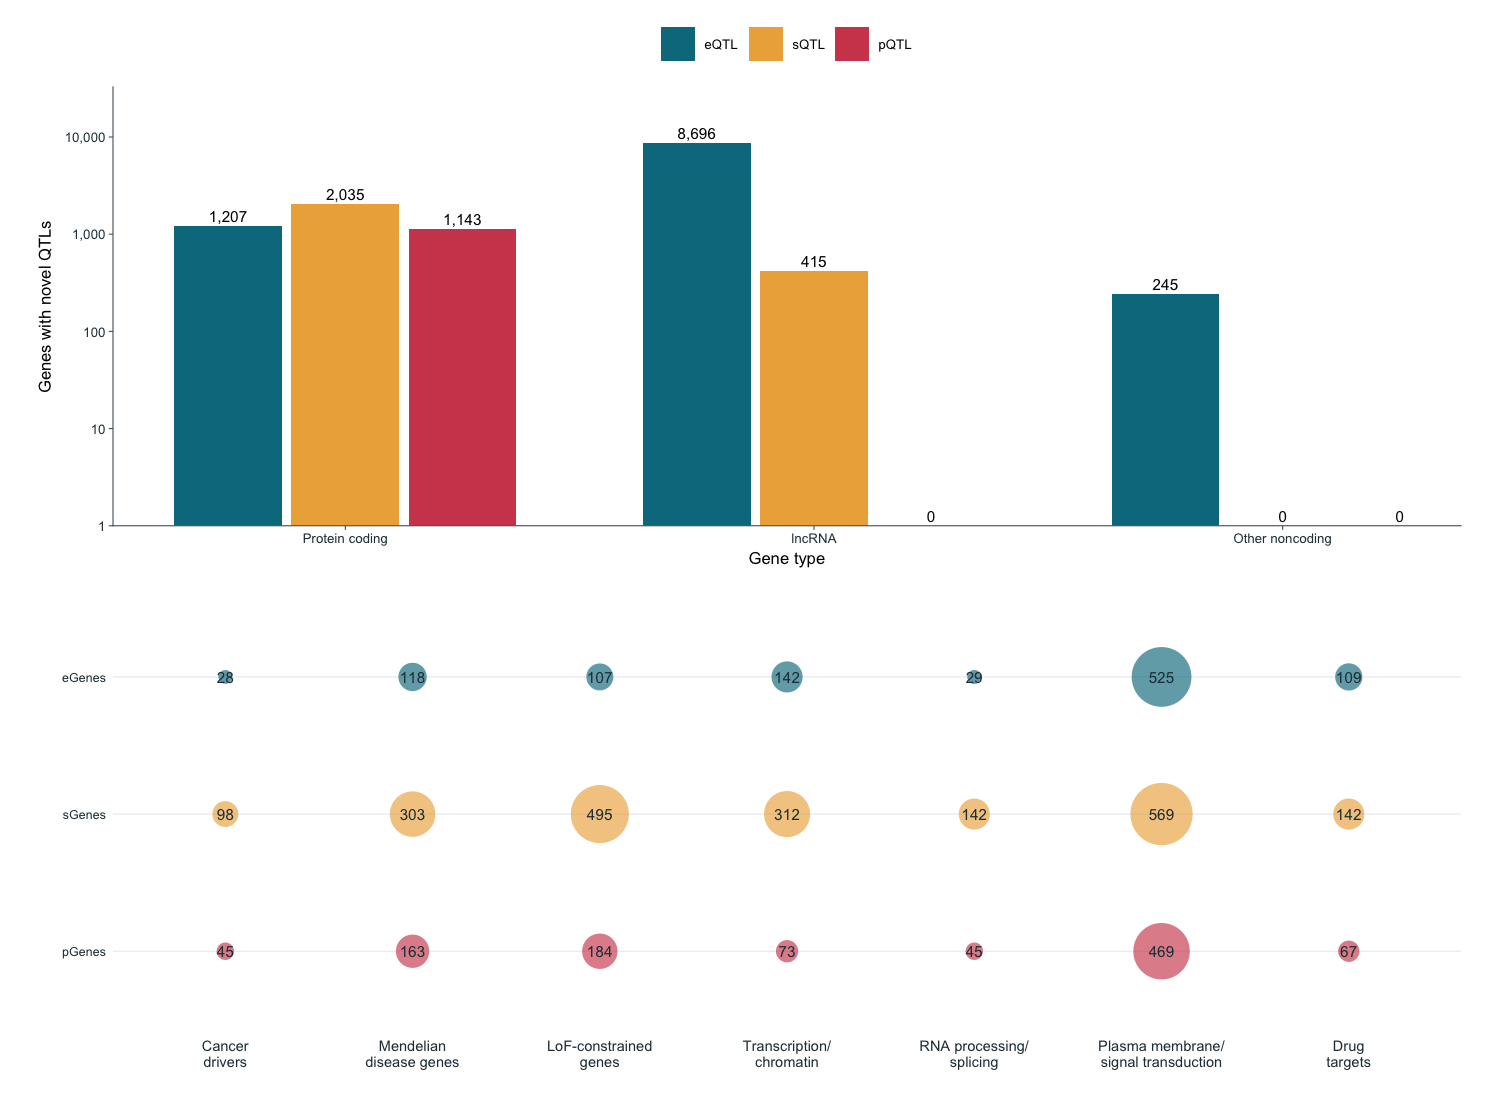

In [5]:
biotype_counts <- novelty %>% filter(novel_for_figure) %>%
  distinct(assay, gene_id, gene_type) %>%
  mutate(biotype = case_when(gene_type == "protein_coding" ~ "Protein coding",
                             gene_type == "lncRNA" ~ "lncRNA", TRUE ~ "Other noncoding"),
         assay = factor(assay, levels = assays),
         biotype = factor(biotype, levels = c("Protein coding", "lncRNA", "Other noncoding"))) %>%
  count(assay, biotype, name = "n_genes") %>%
  complete(assay, biotype, fill = list(n_genes = 0L)) %>%
  mutate(x = as.numeric(biotype) + (as.numeric(assay) - 2) * .25)
category_order <- c("cancer_driver", "mendelian_disease", "lof_constrained",
                    "transcription_chromatin", "rna_processing_splicing",
                    "plasma_membrane_signaling", "drug_target")
category_labels <- c("Cancer\ndrivers", "Mendelian\ndisease genes", "LoF-constrained\ngenes",
                     "Transcription/\nchromatin", "RNA processing/\nsplicing",
                     "Plasma membrane/\nsignal transduction", "Drug\ntargets")
category_counts <- read_figure_tsv(file.path(fig1_categories, "category_counts_by_assay.tsv")) %>%
  mutate(assay = factor(assay, levels = assays), category = factor(category, levels = category_order))
category_genes <- read_figure_tsv(file.path(fig1_categories, "category_gene_lists.tsv"))
category_definitions <- read_figure_tsv(file.path(fig1_categories, "category_definitions.tsv"))
category_check <- category_genes %>% distinct(assay, category, gene_id) %>%
  count(assay, category, name = "recount") %>%
  right_join(category_counts, by = c("assay", "category"))
coding_counts <- biotype_counts %>% filter(biotype == "Protein coding") %>% arrange(assay)
stopifnot(nrow(category_counts) == 21L, nrow(category_definitions) == 7L,
          all(category_check$recount == category_check$n_genes),
          identical(coding_counts$n_genes, c(1207L, 2035L, 1143L)),
          n_distinct(novelty$gene_id[novelty$novel_for_figure &
                                    novelty$gene_type == "protein_coding"]) == 4146L,
          n_distinct(category_genes$gene_id) <= 4146L)
p1C_biotypes <- ggplot(biotype_counts, aes(x, fill = assay)) +
  geom_rect(data = biotype_counts %>% filter(n_genes > 0),
            aes(xmin = x - .115, xmax = x + .115, ymin = 1, ymax = n_genes)) +
  geom_text(aes(y = pmax(n_genes, 1), label = scales::comma(n_genes)),
            vjust = -.4, size = 2.6, family = "Arial") +
  scale_fill_manual(values = assay_colours) +
  scale_x_continuous(breaks = 1:3, labels = levels(biotype_counts$biotype)) +
  scale_y_log10(limits = c(1, 20000), breaks = c(1, 10, 100, 1000, 10000),
                 labels = scales::label_comma(), expand = expansion(mult = c(0, .05))) +
  labs(x = "Gene type", y = "Genes with novel QTLs") + fig1_theme + theme(legend.position = "top")
p1C_categories <- ggplot(category_counts, aes(category, fct_rev(assay))) +
  geom_hline(yintercept = 1:3, colour = "#E7ECF0", linewidth = .25) +
  geom_point(aes(size = n_genes, fill = assay), shape = 21, colour = "transparent", stroke = 0) +
  geom_text(aes(label = n_genes), size = 2.6, family = "Arial", colour = "#263B45") +
  scale_fill_manual(values = scales::alpha(assay_colours, .65), guide = "none") +
  scale_size_area(max_size = 14, guide = "none") +
  scale_x_discrete(labels = set_names(category_labels, category_order), expand = expansion(add = .6)) +
  scale_y_discrete(labels = c(eQTL = "eGenes", sQTL = "sGenes", pQTL = "pGenes")) +
  labs(x = NULL, y = NULL) + theme_minimal(base_size = 7.5, base_family = "Arial") +
  theme(panel.grid = element_blank(), axis.text = element_text(colour = "#263B45"),
        axis.text.x = element_text(size = 7), plot.margin = margin(3, 5, 3, 5, "mm"))
p1C <- p1C_biotypes / p1C_categories + plot_layout(heights = c(1, 1))
save_plot(p1C, "Fig1_C_rebuilt", width_mm = 184, height_mm = 128)
print(p1C)


## Panel D: Credible-set counts in three assays

Each trait contributes once. Only combined-analysis traits with at least one credible set are included.
The numerator counts traits with at least k sets. The denominator is all included traits in the assay.
The final point, 5+, includes all traits with at least five sets. No fine-mapping model is rerun.


Export aggregate plot: Fig1_D_rebuilt


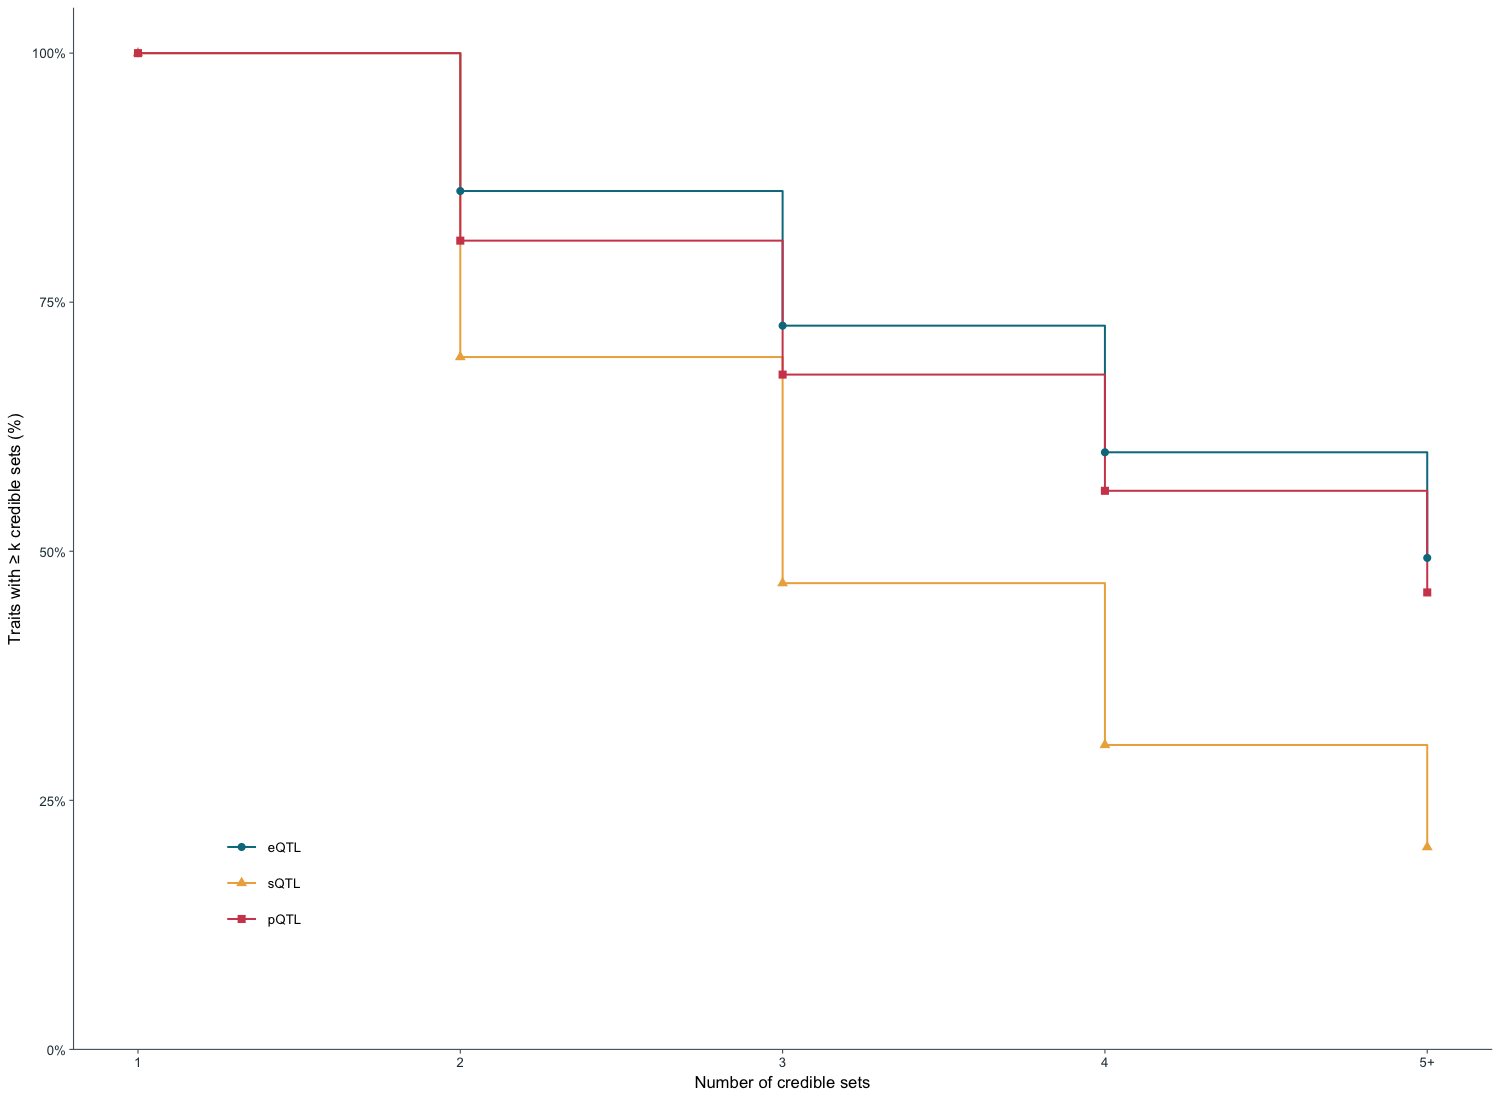

In [6]:
credible_traits <- read_figure_tsv(
  "output/figure1_population_credible_set_counts/credible_sets_per_molecular_trait.tsv.gz") %>%
  filter(population == "COMB") %>% mutate(assay = factor(assay, levels = assays))
credible_totals <- credible_traits %>% group_by(assay) %>%
  summarise(n_traits = n(), n_sets = sum(number_credible_sets), .groups = "drop")
credible_curves <- map_dfr(1:5, function(k) {
  credible_traits %>% group_by(assay) %>%
    summarise(k = k, numerator = sum(number_credible_sets >= k), denominator = n(),
              proportion = mean(number_credible_sets >= k), .groups = "drop")
}) %>% arrange(assay, k)
saved_curves <- read_figure_tsv(file.path(fig1_print, "three_assay_D/credible_set_count_curves.tsv")) %>%
  mutate(assay = factor(assay, levels = assays)) %>% arrange(assay, k)
stopifnot(identical(credible_totals$n_traits, c(29088L, 5763L, 2529L)),
          all(credible_totals$n_sets == c(143512L, 17674L, 11922L)),
          nrow(distinct(credible_traits, assay, molecular_trait_id)) == nrow(credible_traits),
          all(credible_traits$number_credible_sets %in% 1:10),
          isTRUE(all.equal(credible_curves, saved_curves, tolerance = 1e-12)))
p1D <- ggplot(credible_curves, aes(k, proportion, colour = assay, shape = assay)) +
  geom_step(linewidth = .45, direction = "hv") + geom_point(size = 1.65, stroke = .25) +
  scale_colour_manual(values = assay_colours) +
  scale_shape_manual(values = c(eQTL = 16, sQTL = 17, pQTL = 15)) +
  scale_x_continuous(breaks = 1:5, labels = c("1", "2", "3", "4", "5+")) +
  scale_y_continuous(limits = c(0, 1), breaks = seq(0, 1, .25),
                     labels = scales::label_percent(accuracy = 1),
                     expand = expansion(add = c(0, .045))) +
  labs(x = "Number of credible sets", y = "Traits with \u2265 k credible sets (%)") +
  fig1_theme + theme(legend.position = "inside", legend.position.inside = c(.1, .1),
                     legend.justification = c(0, 0))
save_plot(p1D, "Fig1_D_rebuilt", width_mm = 110, height_mm = 65)
print(p1D)


## Panel E: Combined lead-PIP density and high-PIP percentage

Read one maximum variant PIP per credible set from the saved display object.
The density uses bandwidth 0.04 and reflection at 0 and 1, as in the submitted panel.
Each credible set has equal weight. The inset uses unsmoothed counts with a strict PIP > 0.9 threshold.
PIP is a posterior probability. It is not an association P value.


Export aggregate plot: Fig1_E_rebuilt


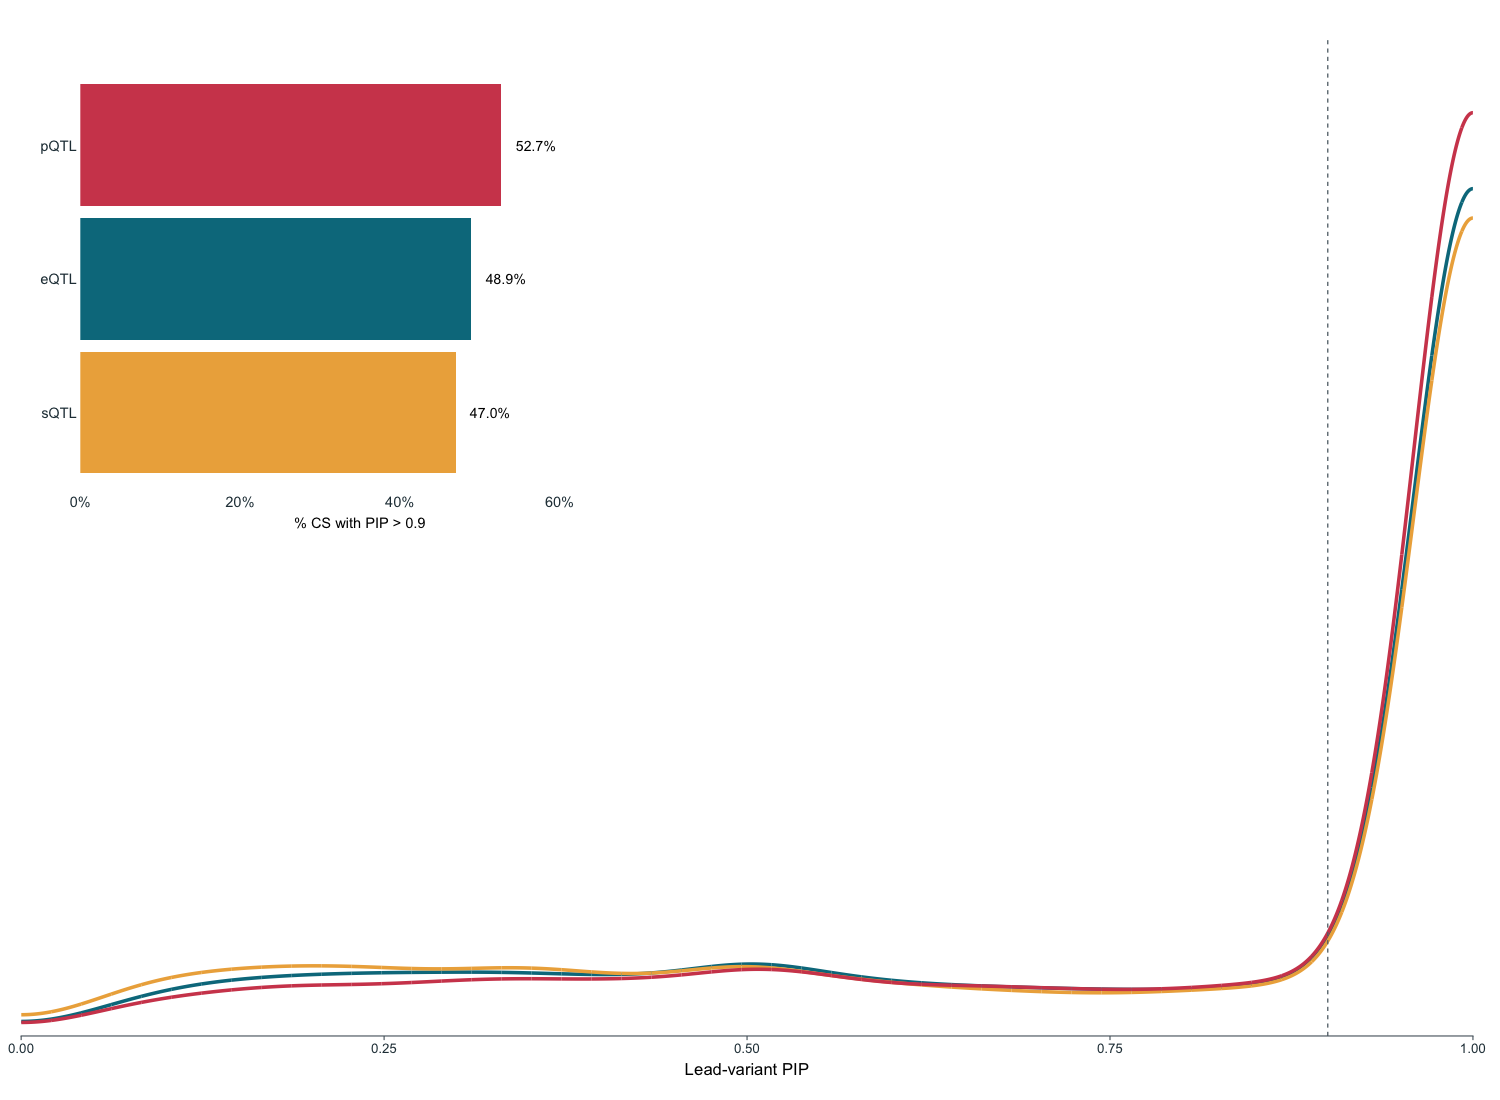

In [7]:
saved_pip <- readRDS(paper_file(file.path(fig1_build,
  "bottom_row_density_options/combined_PIP_percent_inset_display.rds")))
lead_pip <- saved_pip$E$data %>% select(assay, cs_id, lead_pip, group) %>%
  mutate(assay = factor(assay, levels = assays))
pip_summary <- lead_pip %>% group_by(assay) %>%
  summarise(n_cs = n(), median_lead_pip = median(lead_pip),
            n_pip_above_09 = sum(lead_pip > .9), fraction = mean(lead_pip > .9), .groups = "drop") %>%
  mutate(label = sprintf("%.1f%%", 100 * fraction))
stopifnot(all(lead_pip$group == "COMB"), all(is.finite(lead_pip$lead_pip)),
          all(between(lead_pip$lead_pip, 0, 1)),
          nrow(distinct(lead_pip, assay, cs_id)) == nrow(lead_pip),
          identical(pip_summary$n_cs, c(143512L, 17674L, 11922L)),
          identical(pip_summary$n_pip_above_09, c(70246L, 8301L, 6284L)),
          identical(pip_summary$label, c("48.9%", "47.0%", "52.7%")))
p1E_density <- ggplot(lead_pip, aes(lead_pip, colour = assay)) +
  geom_density(bw = .04, bounds = c(0, 1), n = 2048, linewidth = .8) +
  geom_vline(xintercept = .9, colour = "#65727A", linewidth = .3, linetype = "22") +
  scale_colour_manual(values = assay_colours) +
  scale_x_continuous(limits = c(0, 1), breaks = c(0, .25, .5, .75, 1),
                     expand = expansion(mult = 0)) +
  scale_y_continuous(expand = expansion(mult = c(0, .08))) +
  labs(x = "Lead-variant PIP", y = NULL) + fig1_theme +
  theme(legend.position = "none", axis.text.y = element_blank(), axis.ticks.y = element_blank(),
        axis.line.y = element_blank(), plot.margin = margin(5, 3, 2, 2, "mm"))
p1E_inset <- ggplot(pip_summary,
  aes(fraction, fct_rev(factor(assay, levels = c("pQTL", "eQTL", "sQTL"))), fill = assay)) +
  geom_col(width = .91) +
  geom_text(aes(label = label), nudge_x = .018, hjust = 0, size = 2.4, family = "Arial") +
  scale_fill_manual(values = assay_colours, guide = "none") +
  scale_x_continuous(limits = c(0, .7), breaks = c(0, .2, .4, .6),
                     labels = scales::label_percent(accuracy = 1), expand = expansion(mult = 0)) +
  labs(x = "% CS with PIP > 0.9", y = NULL) + fig1_theme +
  theme(axis.text = element_text(size = 7), axis.title.x = element_text(size = 7),
        axis.line.x = element_blank(), axis.line.y = element_blank(), axis.ticks = element_blank(),
        plot.background = element_rect(fill = "white", colour = NA),
        plot.margin = margin(1, 1, 1, 1, "mm"))
rebuilt_density <- ggplot_build(p1E_density)$data[[1]]
saved_density <- ggplot_build(saved_pip$E)$data[[1]]
stopifnot(isTRUE(all.equal(rebuilt_density$x, saved_density$x, tolerance = 1e-12)),
          isTRUE(all.equal(rebuilt_density$density, saved_density$density, tolerance = 1e-12)))
p1E <- p1E_density + inset_element(p1E_inset, left = .01, bottom = .50, right = .43, top = .98)
save_plot(p1E, "Fig1_E_rebuilt", width_mm = 124, height_mm = 70)
print(p1E)


## Exact November 2 submission reference

This is the submitted Figure 1, including the vector artwork, final label spacing, seven categories, post-QC totals, and REM label.
The preceding R panels expose the saved plotting steps. This image is the exact composition used in the submission.


Display the archived November 2 submission image for Figure 1.


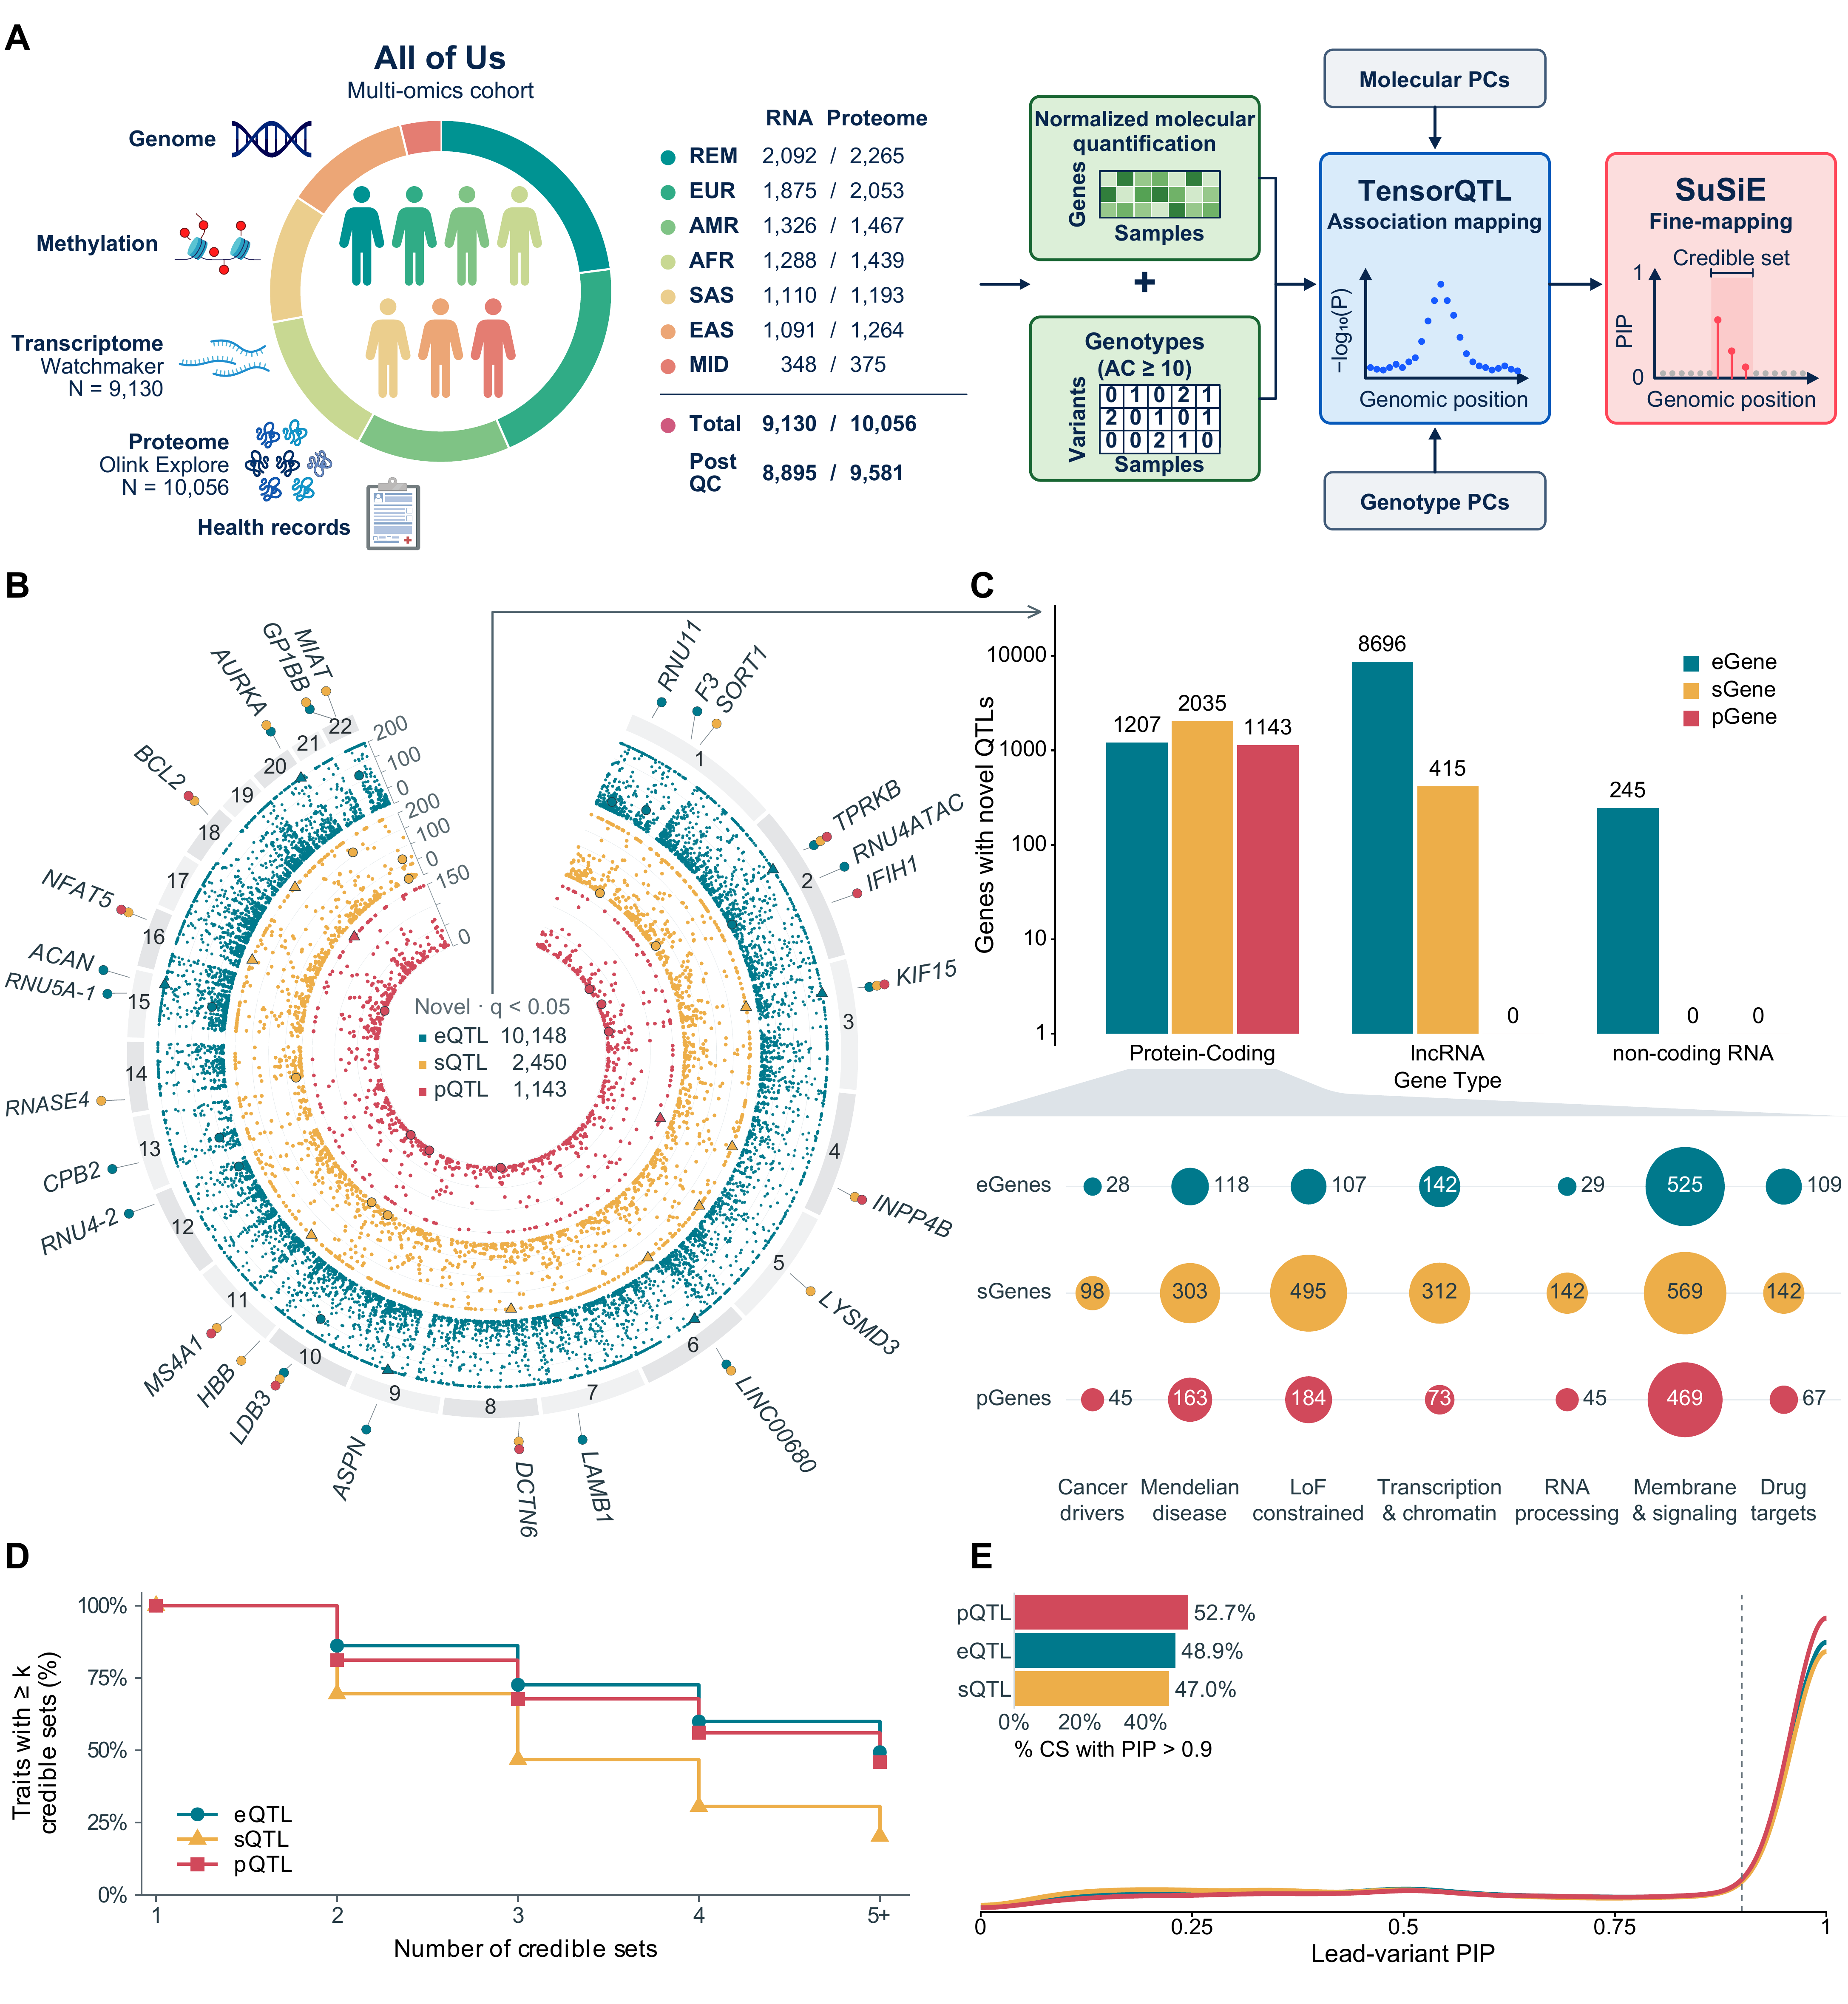

In [8]:
show_reference(1)
